Given below is a Python Implementation, which compares the predictions made by a Traditional Neural Network with those of a Physics Informed Neural Network

---



In [15]:
#Importing the required libraries and modules
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

**1.** Generate Synthetic Data

This is done to mimic the experimental data. We can also add some noise, so that it doesn't look like a perfect parabola

---



In [16]:
#Physics parametrs
g=9.8 #acceleration due to gravity
h0=1.0 #initial height
v0=10.0 #initial velocity

In [17]:
#Analytical (True) Solution
def true_solution(t):
  return h0+v0*t-0.5*g*(t**2)

In [18]:
#Generate some time points
t_min=0
t_max=2
N_data=10
t_data=np.linspace(t_min,t_max,N_data) #Generates a grid of equally spaced time points ranging from t_min to t_max

In [19]:
#Generate Synthetic (Experimental) heights with Noise
np.random.seed(0) #To get repeatable random outputs
noise_level=0.7 #Defines how much pertubration is done to the ideal dataset, to have a dataset that mimics the experimental data
h_data_exact=true_solution(t_data)
h_data_noisy=h_data_exact+noise_level*np.random.randn(N_data)

In [20]:
#Convert to PyTorch Tensors
t_data_tensor=torch.tensor(t_data,dtype=torch.float32, requires_grad=True).view(-1,1)
h_data_tensor=torch.tensor(h_data_noisy,dtype=torch.float32).view(-1,1)

This code converts your NumPy arrays **t_data** and **h_data_noisy** into PyTorch tensors, named **t_data_tensor** and **h_data_tensor**, respectively. The **dtype=torch.float32** argument ensures that the tensors store floating-point numbers with 32-bit precision, which is common in deep learning.The **requires_grad=True** argument for t_data_tensor tells PyTorch to track operations involving t_data_tensor, so that derivatives with respect to time, such as dh/dt, can be calculated later. The **.view(-1, 1)** operation reshapes the tensors from a 1D array into a 2D column vector, which is often required for input into neural networks in PyTorch.

**2.** Define a small feed-forward neural network for h(t)

---



In [21]:
class PINN(nn.Module):
  def __init__(self,n_hidden=20):
    super(PINN,self).__init__()
    #A simple MLP with 2 hidden layers
    self.net=nn.Sequential(
        nn.Linear(1,n_hidden),
        nn.Tanh(),
        nn.Linear(n_hidden,n_hidden),
        nn.Tanh(),
        nn.Linear(n_hidden,1)
    )

  def forward(self,t):
    '''
    Forward pass: input shape (batch_size,1) --> output shape(batch_size)
    '''
    return self.net(t)

#Instantiate the model
model=PINN(n_hidden=20)

**3.** Helper for Automatic Differentiation

This is done to differentiate the neural network

---



In [22]:
#Computes dy/dx using PyTorch's autograd.
def derivative(y,x):
  return torch.autograd.grad(y,x,grad_outputs=torch.ones_like(y),create_graph=True)[0]

This code defines a Python function named **derivative**. Its purpose is to compute the derivative of a tensor **y** with respect to another tensor **x**. It leverages PyTorch's automatic differentiation engine, **torch.autograd.grad**.

- **torch.autograd.grad(y, x, ...)**: This is the core PyTorch function that calculates gradients.
- **grad_outputs=torch.ones_like(y)**: This argument is crucial when **y** is not a scalar (e.g., if it's a vector or a matrix). It acts as a vector of ones with the same shape as **y**, effectively telling PyTorch to sum up the gradients for each element of **y** when computing the gradient with respect to **x**.
- **create_graph=True**: This enables the creation of a computation graph for the derivative itself. This is necessary if you intend to compute *higher-order derivatives* (i.e., the derivative of the derivative).
- **[0]**: The **torch.autograd.grad** function can return gradients for multiple inputs. Since we're only asking for the gradient with respect to **x**, we index **[0]** to retrieve that specific result.

**4.** Define the Loss Components

---

We have:

1) Data loss
2) ODE loss
3) Initial Condition loss



In [23]:
#Compare predicted dh/dt, d(h_pred)/dt with the known values of dh/dt, (v0-gt)
def physics_loss(model,t):
  h_pred=model(t)
  dh_dt_pred=derivative(h_pred,t) #Predicted value of dh/dt

  #For each t, physics says dh/dt=v0-gt
  dh_dt_true=v0-g*t #Known value of dh/dt

  loss_ode=torch.mean((dh_dt_pred-dh_dt_true)**2) #Taking the Mean Squared of Errors
  return loss_ode

In [24]:
 #Compare predicted Initial condition, h0_pred with the known value of Initial condition, h0
def initial_condition_loss(model):

  t0=torch.zeros(1,1,dtype=torch.float32) #Converts the initial time into a tensor for evaluating the initial conditions

  h0_pred=model(t0) #Predicted value of Initial Condition

  loss_ic=torch.mean((h0_pred-h0)**2) #Taking the Mean Squared of Errors
  return loss_ic

In [25]:
#Compare predicted measurements, h_pred with the noisy measurements, h_data
def data_loss(model,t_data,h_data):

  h_pred=model(t_data) #Predicted value of Heights

  loss_data=torch.mean((h_pred-h_data)**2) #Taking the Mean Squared of Errors
  return loss_data

**5.** Training Setup

---



In [26]:
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)

#Hyperparameters for weighing the loss terms
lambda_data=1.0
lambda_ode=0
lambda_ic=0

#For logging
num_epochs=2000
print_every=200

- **optimizer = torch.optim.Adam(model.parameters(), lr=0.01)**:

  This line initializes the **Adam optimizer**, which is a widely used algorithm for training neural networks. It's responsible for adjusting the model's internal parameters (weights and biases) during training to minimize the loss function.
  - **model.parameters()**: provides the optimizer with all the trainable parameters of your PINN model.
  - **lr=0.01**: sets the learning rate to 0.01. The learning rate controls how large of a step the optimizer takes in the direction of the loss gradient during each update.
- **lambda_data = 1.0**, **lambda_ode = 1**, **lambda_ic = 1**:

  - These are **hyperparameters** that act as weights for the different components of your total loss function (data loss, physics loss, and initial condition loss, respectively).
  - By setting them all to 1, you are currently giving equal importance to each of these loss terms when they are combined to form the total loss that the model tries to minimize.
- **num_epochs = 2000**:

  **num_epochs** defines the total number of times the entire training dataset (or in this case, the training process, since we're using a continuous time input) will be passed forward and backward through the neural network. Here, it's set to 2000 iterations.

- **print_every = 200:**

  **print_every** specifies how often (in terms of epochs) the training progress, such as the current loss values, will be printed to the console. Here, it's set to print every 200 epochs.

**6.** Training Loop

---



In [27]:
model.train()
for epoch in range(num_epochs):
  optimizer.zero_grad()

  #Compute losses
  l_data=data_loss(model,t_data_tensor,h_data_tensor) #Calculates the data-driven loss
  l_ode=physics_loss(model,t_data_tensor) #Calculates the phusics-informed loss (or ODE loss)
  l_ic=initial_condition_loss(model) #Calclates the initial condition loss

  #Compute total loss - combines the three individual loss components into a single total loss
  loss=lambda_data*l_data+lambda_ode*l_ode+lambda_ic*l_ic

  #Backpropagatiion and Optimization
  loss.backward() #It computes the gradients of the total loss with respect to all the model's trainable parameters. PyTorch's autograd engine handles this automatically.
  optimizer.step() #This updates the model's parameters using the calculated gradients and the chosen optimization algorithm (Adam, in this case). It adjusts the weights and biases to reduce the total loss.

  #Print progress
  if (epoch+1)%print_every==0:
    print(f"Epoch {epoch+1}/{num_epochs}, "
    f"Total Loss = {loss.item():.6f}"
    f"Data Loss = {l_data.item():.6f}"
    f"ODE Loss = {l_ode.item():.6f}"
    f"IC Loss = {l_ic.item():.6f}")

Epoch 200/2000, Total Loss = 1.153749Data Loss = 1.153749ODE Loss = 16.211666IC Loss = 1.502931
Epoch 400/2000, Total Loss = 0.121740Data Loss = 0.121740ODE Loss = 18.012627IC Loss = 1.518991
Epoch 600/2000, Total Loss = 0.081730Data Loss = 0.081730ODE Loss = 16.475399IC Loss = 1.520216
Epoch 800/2000, Total Loss = 0.069537Data Loss = 0.069537ODE Loss = 18.762354IC Loss = 1.529492
Epoch 1000/2000, Total Loss = 0.065573Data Loss = 0.065573ODE Loss = 21.891459IC Loss = 1.531285
Epoch 1200/2000, Total Loss = 0.063255Data Loss = 0.063255ODE Loss = 24.655157IC Loss = 1.528881
Epoch 1400/2000, Total Loss = 0.061075Data Loss = 0.061075ODE Loss = 26.574488IC Loss = 1.525723
Epoch 1600/2000, Total Loss = 0.041226Data Loss = 0.041226ODE Loss = 19.652985IC Loss = 1.522414
Epoch 1800/2000, Total Loss = 0.008115Data Loss = 0.008115ODE Loss = 17.643419IC Loss = 1.521706
Epoch 2000/2000, Total Loss = 0.000647Data Loss = 0.000647ODE Loss = 15.955847IC Loss = 1.523075


As evident, all the individual losses, and hence the total loss is decreasing with increasing number of epochs

- **model.train()**:

  This line sets the model to **training mode**. In PyTorch, this is important because some layers (like BatchNorm or Dropout) behave differently during training versus evaluation. For your simple MLP, it might not have a direct effect, but it's good practice.

- **for epoch in range(num_epochs)**:

  This initiates the main training loop, which will run for a specified number of **num_epochs** (in your case, 2000 iterations).

- **optimizer.zero_grad()**:

  Before computing gradients for the current epoch, it's crucial to clear any previously accumulated gradients. If you don't do this, gradients from previous backward passes would be added to the current ones, leading to incorrect updates.


**7.** Evaluate the Trained Model

---



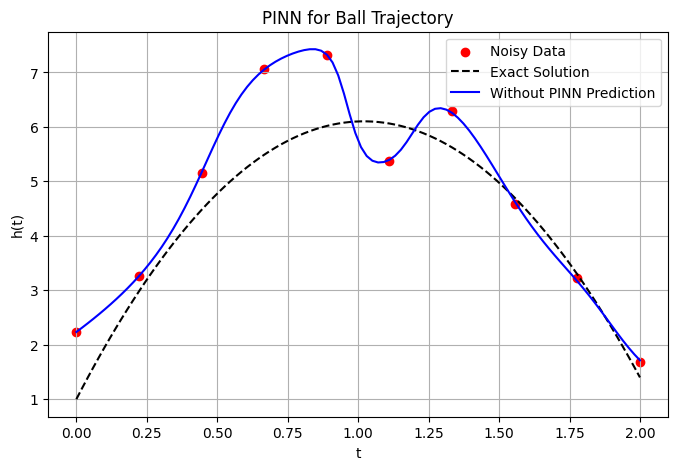

In [28]:
model.eval()
t_plot=np.linspace(t_min,t_max,100).reshape(-1,1).astype(np.float32)
t_plot_tensor=torch.tensor(t_plot,requires_grad=True)
h_pred_plot=model(t_plot_tensor).detach().numpy()

#True solution (For Comparison)
h_true_plot=true_solution(t_plot)

#Plot Results
plt.figure(figsize=(8,5))
plt.scatter(t_data,h_data_noisy,color="red",label="Noisy Data")
plt.plot(t_plot,h_true_plot,"k--",label="Exact Solution")
plt.plot(t_plot,h_pred_plot,"b",label="Without PINN Prediction")
plt.xlabel("t")
plt.ylabel("h(t)")
plt.legend()
plt.title("PINN for Ball Trajectory")
plt.grid(True)
plt.show()

As evident, the initial condition is being satisfied. Instead of the neural network fitting perfectly through the noisy data, it takes help from the physics of the system and aligns its predictions, such that it doesn't ignore the experiments completely, but also doesn't ignore the physics.

Try the following:

- Increase the weightage given to ODE loss.

- Increase the wightage given to ODE loss and IC loss, and decrease the weightage given to Data loss.

- Give zero weightage to the ODE loss, and 1 each to Data loss and IC loss

- Give zero weightage to the ODE loss and IC loss, and 1 to Data Loss

In each of the above case, analyse how much the predictions will come closer to the ideal solution.